In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder,OneHotEncoder,StandardScaler,MinMaxScaler,FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline,make_pipeline

In [4]:
housing=pd.read_csv('1553768847-housing.csv')

In [5]:
housing.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  int64  
 3   total_rooms         20640 non-null  int64  
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  int64  
 6   households          20640 non-null  int64  
 7   median_income       20640 non-null  float64
 8   ocean_proximity     20640 non-null  str    
 9   median_house_value  20640 non-null  int64  
dtypes: float64(4), int64(5), str(1)
memory usage: 1.7 MB


In [6]:
housing.dtypes

longitude             float64
latitude              float64
housing_median_age      int64
total_rooms             int64
total_bedrooms        float64
population              int64
households              int64
median_income         float64
ocean_proximity           str
median_house_value      int64
dtype: object

In [7]:
housing.columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'ocean_proximity', 'median_house_value'],
      dtype='str')

In [8]:
housing["ocean_proximity"].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

In [9]:
housing.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [10]:
target="median_house_value"
colonnes=[col for col in housing.columns if col!=target]
colonnes

['longitude',
 'latitude',
 'housing_median_age',
 'total_rooms',
 'total_bedrooms',
 'population',
 'households',
 'median_income',
 'ocean_proximity']

In [11]:
y=housing[[target]]
X=housing[colonnes]

In [12]:
X.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity
0,-122.23,37.88,41,880,129.0,322,126,8.3252,NEAR BAY
1,-122.22,37.86,21,7099,1106.0,2401,1138,8.3014,NEAR BAY
2,-122.24,37.85,52,1467,190.0,496,177,7.2574,NEAR BAY
3,-122.25,37.85,52,1274,235.0,558,219,5.6431,NEAR BAY
4,-122.25,37.85,52,1627,280.0,565,259,3.8462,NEAR BAY


In [13]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

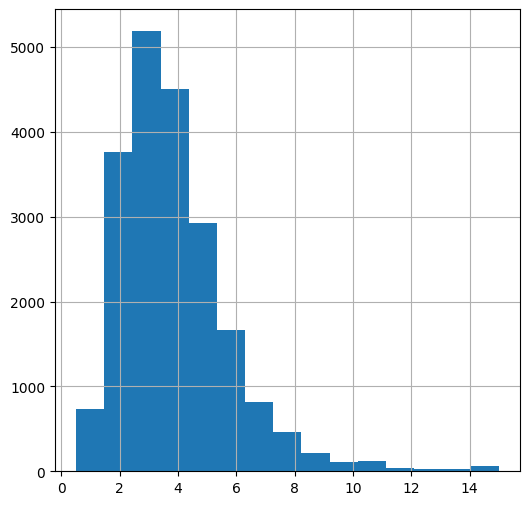

In [14]:
housing['median_income'].hist(bins=15,figsize=(6,6))
plt.show()
#max=15

In [15]:
#max=15
#so I'm gonna cut it into 5 categrories
housing['income_cat']=pd.cut(housing['median_income'],bins=[0,1.5,3,4.5,6,np.inf],labels=[1,2,3,4,5])

In [16]:
housing['income_cat'].value_counts()

income_cat
3    7236
2    6581
4    3639
5    2362
1     822
Name: count, dtype: int64

<Axes: xlabel='income_cat'>

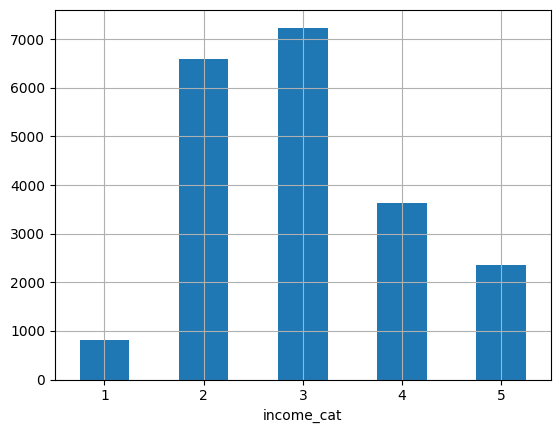

In [17]:
housing['income_cat'].value_counts().sort_index().plot.bar(rot=0,grid=True)

In [18]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=housing['income_cat'])

In [19]:

# for set_ in (X_train,X_test,y_train,y_test):
#     set_.drop("income_cat",axis=1,inplace=True)

In [20]:
housing.drop('income_cat',inplace=True,axis=1)

In [21]:
housing.columns

Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'ocean_proximity', 'median_house_value'],
      dtype='str')

In [22]:
#explore and visualize data to get insights
housing=housing.copy()

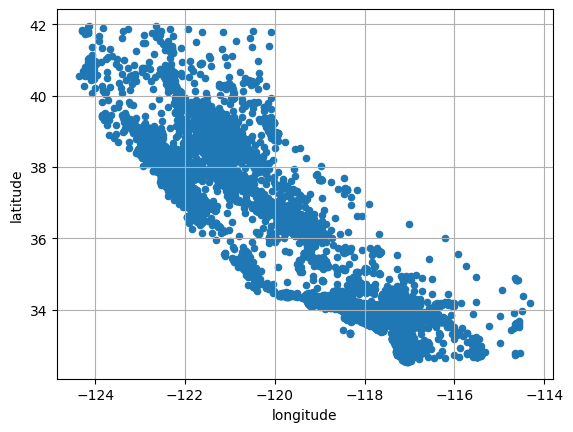

In [23]:
#visualize geopraphical data
housing.plot(kind="scatter",x="longitude",y="latitude")
plt.grid(True)
plt.show()

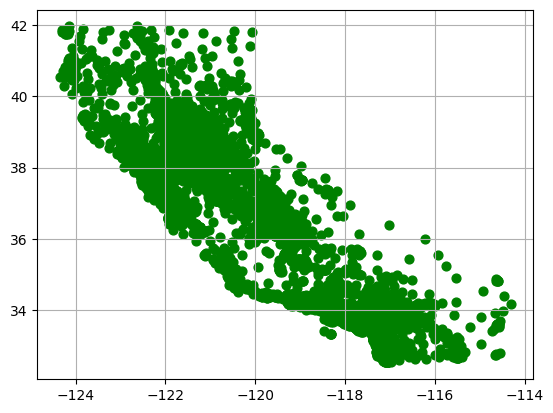

In [24]:
plt.scatter(housing["longitude"],housing['latitude'],c="green",s=40)
plt.grid(True)
plt.show()

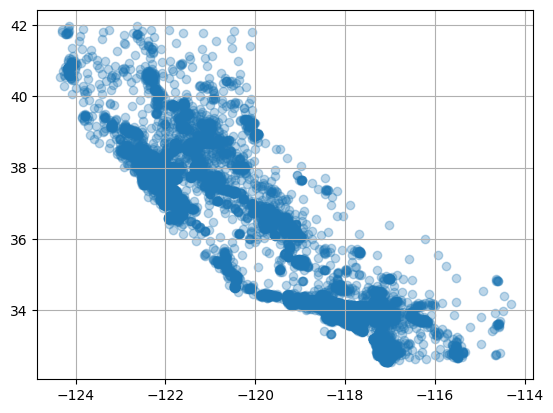

In [25]:
plt.scatter(housing['longitude'],housing['latitude'],alpha=0.3)
plt.grid(True)
plt.show()
#so we will notice that the color in dark in the areas where the is more houses namely Bay area...

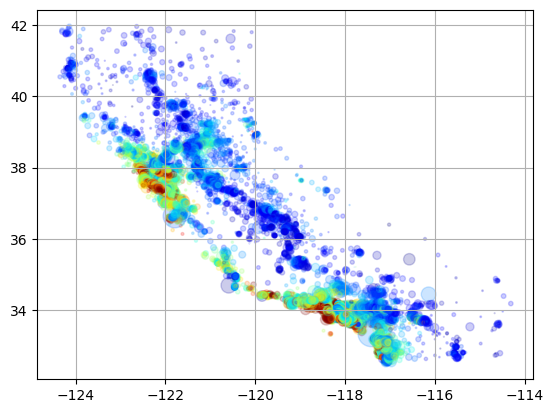

In [26]:
#the cercle=the popluation 
#color=the price
plt.scatter(housing['longitude'],housing['latitude'],s=housing['population']/100,label="population",cmap="jet",c=housing["median_house_value"],alpha=0.2)
plt.grid(True)
plt.show()

In [27]:
#so here we notice that the prices are very much related to the location -the expensive houses are close to the ocean


In [28]:
#look for correlation
corr_columns=[col for col in housing.columns if col!="ocean_proximity"]
corr_matrix=housing[corr_columns].corr()

In [29]:
corr_matrix

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
longitude,1.000000,-0.924664,-0.108197,0.044568,0.069608,0.099773,0.055310,-0.015176,-0.045967
latitude,-0.924664,1.000000,0.011173,-0.036100,-0.066983,-0.108785,-0.071035,-0.079809,-0.144160
housing_median_age,-0.108197,0.011173,1.000000,-0.361262,-0.320451,-0.296244,-0.302916,-0.119034,0.105623
total_rooms,0.044568,-0.036100,-0.361262,1.000000,0.930380,0.857126,0.918484,0.198050,0.134153
total_bedrooms,0.069608,-0.066983,-0.320451,0.930380,1.000000,0.877747,0.979728,-0.007723,0.049686
population,0.099773,-0.108785,-0.296244,0.857126,0.877747,1.000000,0.907222,0.004834,-0.024650
households,0.055310,-0.071035,-0.302916,0.918484,0.979728,0.907222,1.000000,0.013033,0.065843
median_income,-0.015176,-0.079809,-0.119034,0.198050,-0.007723,0.004834,0.013033,1.000000,0.688075
median_house_value,-0.045967,-0.144160,0.105623,0.134153,0.049686,-0.024650,0.065843,0.688075,1.000000


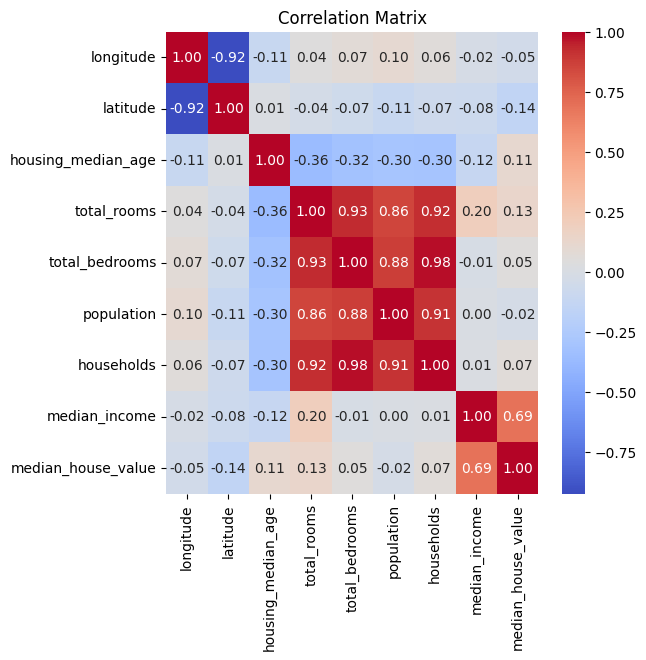

In [30]:
plt.figure(figsize=(6,6))
sns.heatmap(corr_matrix,annot=True,cmap="coolwarm",fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

In [31]:
corr_matrix['median_house_value'].sort_values(ascending=False)
#that's true the median income column  is very important to predict the price
#the lower the latitude the higher the price 

median_house_value    1.000000
median_income         0.688075
total_rooms           0.134153
housing_median_age    0.105623
households            0.065843
total_bedrooms        0.049686
population           -0.024650
longitude            -0.045967
latitude             -0.144160
Name: median_house_value, dtype: float64

In [32]:
#expriment with attribute combinaisons
housing['rooms_per_house']=housing['total_rooms']/housing['households']
housing["bedrooms_per_house"]=housing['total_bedrooms']/housing['households']
housing['bedrooms_ratio']=housing['total_bedrooms']/housing["total_rooms"]
housing["people_per_house"]=housing["population"]/housing["households"]

In [33]:
housing.columns
corr_columns=[col for col in housing.columns if col!="ocean_proximity"]

In [34]:
#then we look at the correlation matrix again
corr_matrix=housing[corr_columns].corr()['median_house_value'].sort_values(ascending=False)
corr_matrix

median_house_value    1.000000
median_income         0.688075
rooms_per_house       0.151948
total_rooms           0.134153
housing_median_age    0.105623
households            0.065843
total_bedrooms        0.049686
people_per_house     -0.023737
population           -0.024650
longitude            -0.045967
bedrooms_per_house   -0.046739
latitude             -0.144160
bedrooms_ratio       -0.255880
Name: median_house_value, dtype: float64

In [35]:
#the lower bedrooms ratio the higher the price
#so if number of rooms > number of bedrooms -> high price

In [36]:
#prepare data for machine learning algorithms
housing=housing.drop('median_house_value',axis=1)

In [37]:
missing=housing.isnull().sum()
missing=missing[missing>0].sort_values()
missing

total_bedrooms        207
bedrooms_per_house    207
bedrooms_ratio        207
dtype: int64

In [38]:
missing_df=pd.DataFrame({'missing_count':missing,'missing %':((missing/len(housing))*100).round(3)})
missing_df

,missing_count,missing %
total_bedrooms,207,1.003
bedrooms_per_house,207,1.003
bedrooms_ratio,207,1.003


In [39]:
#clean the data
imputer=SimpleImputer(strategy="median")


In [40]:
housing_num=housing.select_dtypes(include=[np.number])

In [41]:
imputer.fit(housing_num)

,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a feature has nomissing values at fit/train time, the feature won't appear onthe missing indicator even if there are missing values attransform/test time.",False
,"keep_empty_features keep_empty_features: bool, default=FalseIf True, features that consist exclusively of missing values when`fit` is called are returned in results when `transform` is called.The imputed value is always `0` except when `strategy=""constant""`in which case `fill_value` will be used instead... versionadded:: 1.2",False


In [42]:
#X= numpy array
X=imputer.fit_transform(housing_num) #sklearn transformers output numpy arrays 


In [43]:
#handling text and categorical attributes
housing_cat=housing[['ocean_proximity']]


In [44]:
one_hot_encoder=OneHotEncoder()
housing_encoded=one_hot_encoder.fit_transform(housing_cat)

In [45]:
housing_encoded

<20640x5 sparse matrix of type '<class 'numpy.float64'>'
	with 20640 stored elements in Compressed Sparse Row format>

In [46]:
#X fit transform mais pour y juste transform


In [47]:
housing_encoded.toarray()

array([[0., 0., 0., 1., 0.],
       [0., 0., 0., 1., 0.],
       [0., 0., 0., 1., 0.],
       ...,
       [0., 1., 0., 0., 0.],
       [0., 1., 0., 0., 0.],
       [0., 1., 0., 0., 0.]])

In [48]:
#feature scaling and transformations
scaler=StandardScaler()
housing_scaled=scaler.fit_transform(housing_num)

In [51]:
#before we scale the feature we should first transform it to shrink the heavy tail and if possible to make the distribution roughly symmetrical
log_transformer=FunctionTransformer(np.log,inverse=np.exp)
log_pop=log_transformer.transform(housing[["population"]])

TypeError: FunctionTransformer.__init__() got an unexpected keyword argument 'inverse'

In [54]:
#transformations pipeline
pipeline=make_pipeline(SimpleImputer(strategy="median"),StandardScaler())